# Random-base factoring with recycled-control circuits

This notebook executes actual modular arithmetic and measured statevector trajectories. Full failures, classical gcd successes, reset/feedback work and cap transitions remain visible. A separate ideal-policy audit uses a bounded reference and is never consulted by the algorithm sampler. No adaptive physical or formal certificate is supplied.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "src").exists() and (root.parent / "src").exists():
    root = root.parent
if (root / "src").exists():
    sys.path.insert(0, str(root / "src"))
from openquantum.shor_driver import (
    FactoringConfig, build_iterative_order_circuit, factor_with_quantum_trials,
    numerical_policy_audit, prime_factorization, iterative_distribution,
)
import matplotlib.pyplot as plt
import numpy as np


## Actual adaptive circuit

The four-stage N=15,a=2 diagram is a compact illustration of measurement and classical feedback. Complete runs below use the default t=2n policy: t=8 or10. Every arithmetic box has an explicit gate definition. All wires reset for each complete quantum trial.

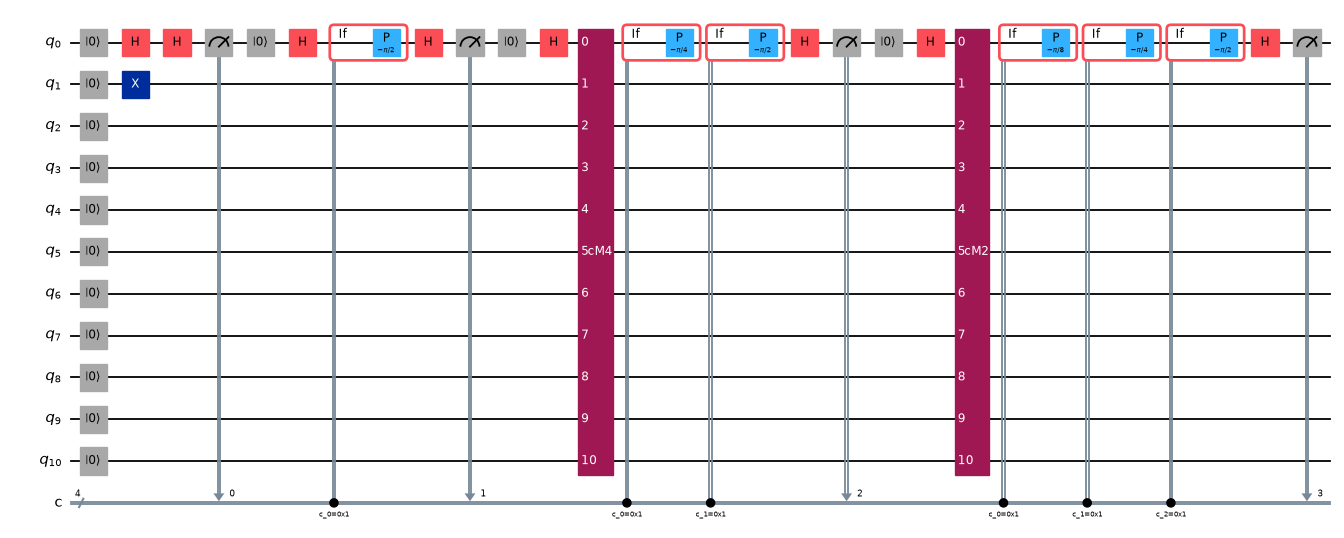

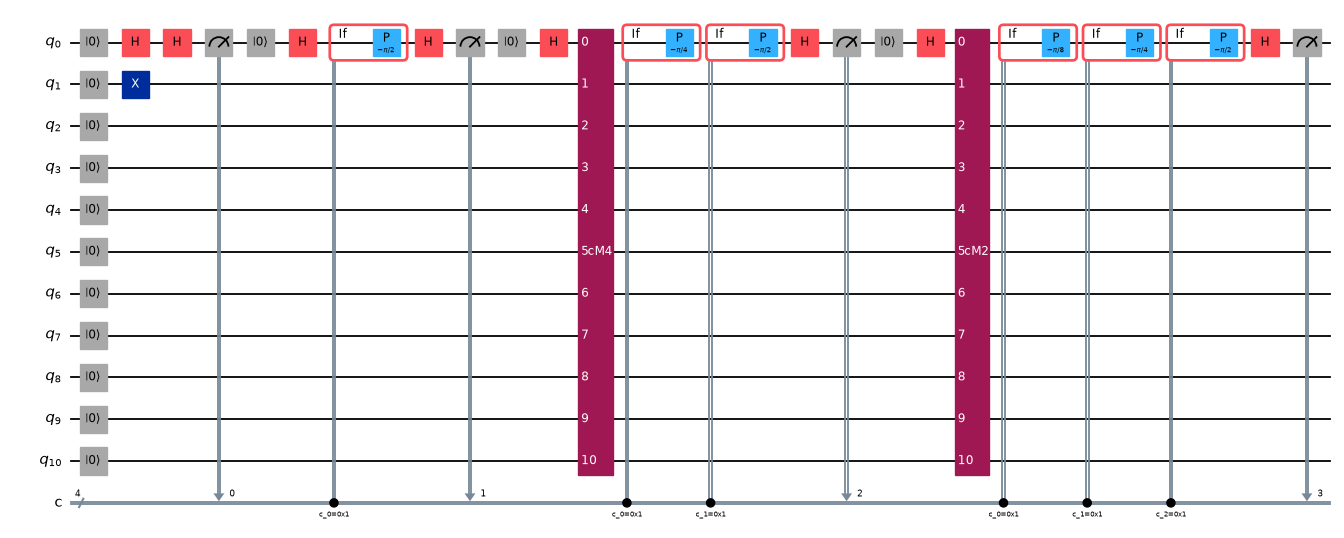

In [2]:
small_circuit = build_iterative_order_circuit(15, 2, 4)
small_circuit.draw(output="mpl", fold=36, scale=0.65)

## A random-base quantum success

The seed and the whole stopping policy are fixed before execution. The driver chooses bases uniformly with replacement; it does not read a reference order.

In [3]:
config = FactoringConfig(seed=1)
run = factor_with_quantum_trials(21, config=config)
assert run["status"] == "factored_quantum_trial"
assert run["factors"] == [3, 7]
assert run["quantum_trials"] == 1 and run["peak_logical_qubits"] == 13
{"status": run["status"], "factors": run["factors"], "base_draws": run["base_draws"],
 "complete_quantum_trials": run["quantum_trials"], "phase_bits": run["phase_bits"],
 "primitive_operations": run["executed_quantum_primitive_operations"],
 "gate_counts": run["executed_quantum_primitive_counts"]}

{'status': 'factored_quantum_trial',
 'factors': [3, 7],
 'base_draws': 1,
 'complete_quantum_trials': 1,
 'phase_bits': 10,
 'primitive_operations': 75799,
 'gate_counts': {'rz': 38666,
  'cx': 33228,
  'h': 3313,
  'ry': 209,
  't': 200,
  'tdg': 150,
  'reset': 22,
  'measure': 10,
  'x': 1}}

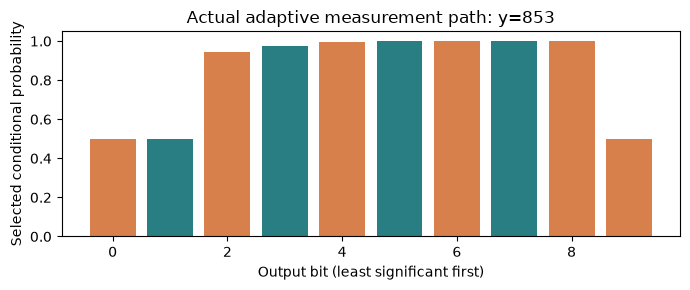

In [4]:
attempt = run["trace"][0]["quantum_attempts"][0]
assert attempt["outcome"] == 853
steps = attempt["steps"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([s["output_bit"] for s in steps], [s["selected_conditional_probability"] for s in steps],
       color=["#d7804c" if s["measured_bit"] else "#287e83" for s in steps])
ax.set(xlabel="Output bit (least significant first)", ylabel="Selected conditional probability",
       title="Actual adaptive measurement path: y=853", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

## Failed quantum work followed by a classical factor

A later gcd success does not cancel the two complete failed quantum trials. The exhausted example uses the same caps and provides no false success label.

In [5]:
retry = factor_with_quantum_trials(15, config=FactoringConfig(seed=1, max_base_draws=3, shots_per_coprime_base=1, max_quantum_trials=3))
exhausted = factor_with_quantum_trials(15, config=FactoringConfig(seed=20261112, max_base_draws=3, shots_per_coprime_base=1, max_quantum_trials=3))
assert retry["quantum_trials"] == 2 and retry["status"] == "factored_classical_gcd"
assert exhausted["quantum_trials"] == 3 and exhausted["factors"] == []
[{"seed": x["config"]["seed"], "status": x["status"], "complete_trials": x["quantum_trials"],
  "bases": [d["base"] for d in x["trace"]], "primitive_operations": x["executed_quantum_primitive_operations"]}
 for x in (retry, exhausted)]

[{'seed': 1,
  'status': 'factored_classical_gcd',
  'complete_trials': 2,
  'bases': [8, 8, 6],
  'primitive_operations': 17302},
 {'seed': 20261112,
  'status': 'exhausted_base_draws',
  'complete_trials': 3,
  'bases': [14, 13, 14],
  'primitive_operations': 18489}]

## Full prime-factor wrapper and an independent policy audit

The recursive wrapper resolves composite components and shares one global trial cap. Its execution is a separate run. The numerical audit computes an ideal-policy probability using reference distributions, including caps inside and between base choices; it is not a physical confidence certificate.

In [6]:
complete = prime_factorization(225, config=FactoringConfig(seed=1))
assert complete["prime_factors"] == [3, 3, 5, 5]
assert complete["unresolved_components"] == []
assert complete["quantum_trials"] <= complete["global_quantum_cap"]
audit = numerical_policy_audit(15, FactoringConfig())
assert abs(audit["ideal_failure_probability"] - (5/26)**8) < 1e-14
{"prime_factors_225": complete["prime_factors"], "whole_recursive_trials": complete["quantum_trials"],
 "reference_policy_failure_N15": audit["ideal_failure_probability"],
 "confidence_certified": audit["is_certified_confidence_bound"]}

{'prime_factors_225': [3, 3, 5, 5],
 'whole_recursive_trials': 2,
 'reference_policy_failure_N15': 1.8705669248050803e-06,
 'confidence_certified': False}

## Optional bounded live controls

A live Python kernel can change input and caps. Static publication skips widgets. These controls execute real small circuits, not a hidden order oracle; the local simulation and compilation time can take a few seconds. Hosted Binder provisioning is not verified by this notebook.

In [7]:
import os
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    modulus = widgets.Dropdown(options=[15, 21], value=21, description="N")
    seed = widgets.IntSlider(min=0, max=4, value=1, description="seed")
    bases = widgets.IntSlider(min=1, max=4, value=3, description="base cap")
    shots = widgets.IntSlider(min=1, max=2, value=1, description="shots/base")
    trial_cap = widgets.IntSlider(min=1, max=4, value=3, description="trial cap")
    button = widgets.Button(description="Run actual driver")
    output = widgets.Output()
    def evaluate(_):
        with output:
            clear_output(wait=True)
            result = factor_with_quantum_trials(modulus.value, config=FactoringConfig(
                seed=seed.value, max_base_draws=bases.value,
                shots_per_coprime_base=shots.value, max_quantum_trials=trial_cap.value))
            display({"status": result["status"], "factors": result["factors"],
                     "bases": [row["base"] for row in result["trace"]],
                     "complete_quantum_trials": result["quantum_trials"],
                     "primitive_operations": result["executed_quantum_primitive_operations"]})
    button.on_click(evaluate)
    display(widgets.VBox([modulus, seed, bases, shots, trial_cap, button, output]))


The generator `python scripts/generate_shor_driver.py --recursive` emits exact source hashes, the complete actual trace, a lowered adaptive QASM program and its branch-count policy. Reset and feedback faults/latency still need a compatible physical model; the static QDK adapter must not be applied after removing those operations. Numerical tests do not provide an integrated Lean proof.